=== PIXEL TENSOR STATISTICS ===
Original Shape   : (720, 1280, 3)
Preprocessed Shape: (640, 640, 3)
Min Pixel Value  : 0.0000
Max Pixel Value  : 0.4471
Data Type        : float32


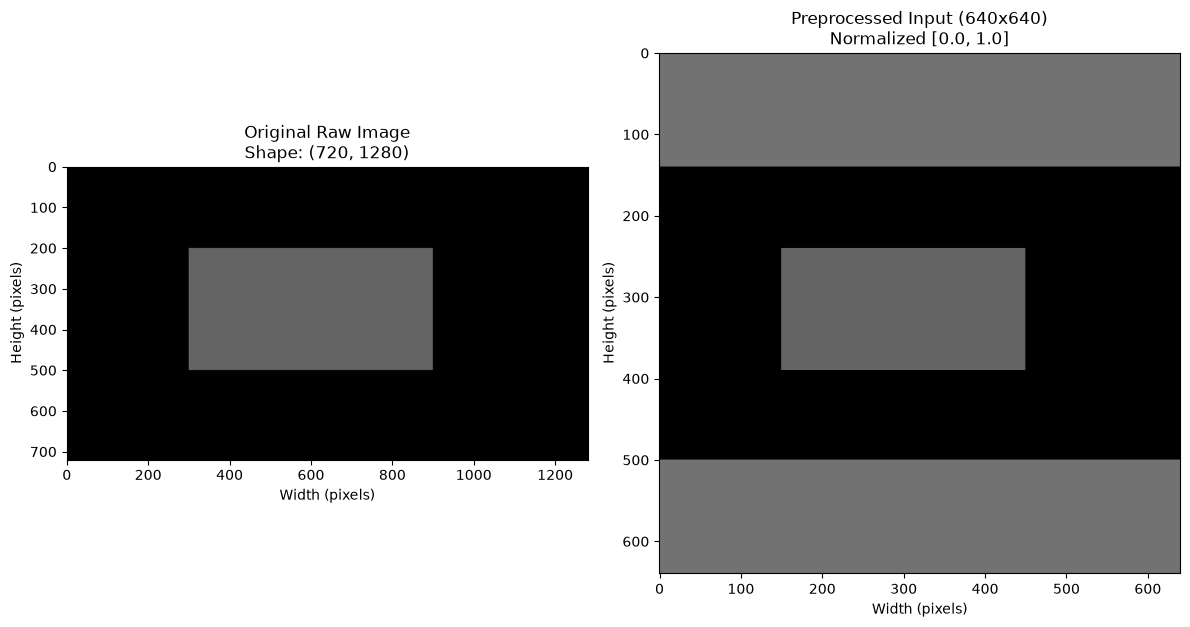

<Figure size 640x480 with 0 Axes>

In [5]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Load high-resolution traffic scene image (or generate fallback synthetic image)
img_path = "../data/traffic.jpg"
raw_img = cv2.imread(img_path)

if raw_img is None:
    raw_img = np.zeros((1080, 1920, 3), dtype=np.uint8)
    cv2.rectangle(
        raw_img, (200, 400), (1000, 900), (120, 120, 120), -1
    )  # Road segment
    cv2.rectangle(
        raw_img, (400, 500), (600, 700), (0, 0, 255), -1
    )  # Vehicle representation

# Convert BGR (OpenCV default) to RGB for Matplotlib visualization
rgb_orig = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)

# 2. Resize image to standard 640x640 using aspect-ratio letterboxing
target_size = (640, 640)
h, w = raw_img.shape[:2]
scale = min(target_size[0] / h, target_size[1] / w)
new_w, new_h = int(w * scale), int(h * scale)

resized = cv2.resize(raw_img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

# Letterbox padding to reach exact 640x640 dimensions
top = (target_size[0] - new_h) // 2
bottom = target_size[0] - new_h - top
left = (target_size[1] - new_w) // 2
right = target_size[1] - new_w - left

letterboxed = cv2.copyMakeBorder(
    resized,
    top,
    bottom,
    left,
    right,
    cv2.BORDER_CONSTANT,
    value=[114, 114, 114],
)

# 3. Normalize pixel values from [0, 255] to floating-point [0.0, 1.0]
normalized_tensor = letterboxed.astype(np.float32) / 255.0

# Print pixel tensor statistics
print("=== PIXEL TENSOR STATISTICS ===")
print(f"Original Shape   : {raw_img.shape}")
print(f"Preprocessed Shape: {normalized_tensor.shape}")
print(f"Min Pixel Value  : {normalized_tensor.min():.4f}")
print(f"Max Pixel Value  : {normalized_tensor.max():.4f}")
print(f"Data Type        : {normalized_tensor.dtype}")

# 4. Display original and preprocessed images side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(rgb_orig)
axes[0].set_title(f"Original Raw Image\nShape: {raw_img.shape[:2]}")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Height (pixels)")

rgb_preprocessed = cv2.cvtColor(letterboxed, cv2.COLOR_BGR2RGB)
axes[1].imshow(rgb_preprocessed)
axes[1].set_title(f"Preprocessed Input (640x640)\nNormalized [0.0, 1.0]")
axes[1].set_xlabel("Width (pixels)")
axes[1].set_ylabel("Height (pixels)")

plt.tight_layout()
plt.show()
axes[1].set_ylabel("Height (pixels)")

plt.tight_layout()
plt.show()